<a href="https://colab.research.google.com/github/AnusuyaDandapat/MLOpsLab/blob/main/MLOps_exp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANUSUYA DANDAPAT 23MT7006


In [ ]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
# 2. Load Dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("\nFirst Five Rows:")
print(X.head())

Dataset Shape: (569, 30)

First Five Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [ ]:
# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# 4. Create ML Pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])


Training Samples: 455
Testing Samples: 114


In [ ]:
# 5. Train the Model
pipeline.fit(X_train, y_train)
print("\nModel Training Completed!")


Model Training Completed!


In [ ]:
# 6. Make Predictions
y_pred = pipeline.predict(X_test)

# 7. Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print("\nClassification Results")
print("----------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


Classification Results
----------------------
Accuracy: 95.61 %

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



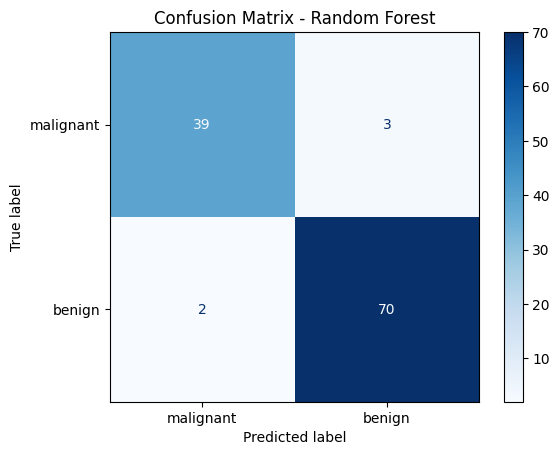

In [ ]:
# 8. Display Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)
display.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.show()

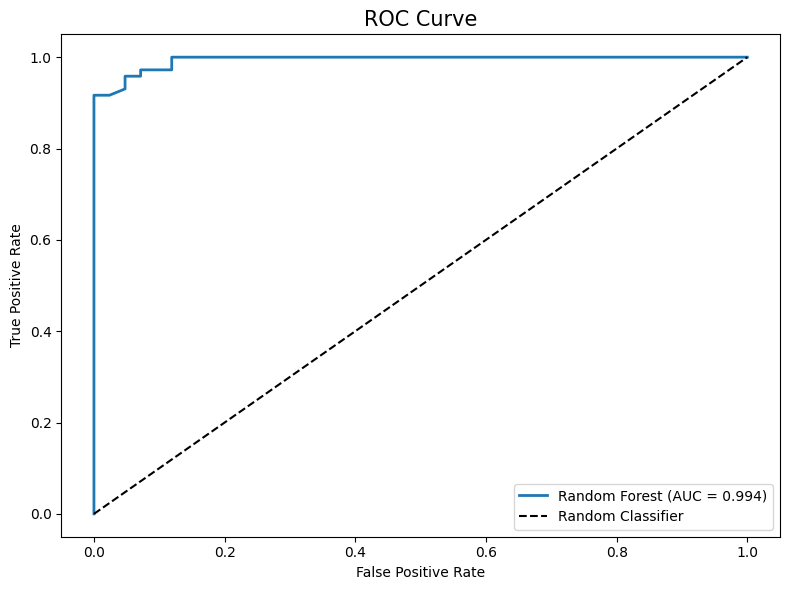

ROC-AUC Score: 0.9939


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities for the positive class
y_prob = pipeline.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Random Forest (AUC = {auc_score:.3f})",
    linewidth=2
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve", fontsize=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

In [ ]:
# 9. Predict a Sample
sample = X_test.iloc[[0]]
prediction = pipeline.predict(sample)[0]

print("\nSample Prediction:", data.target_names[prediction])
print("Actual Class:", data.target_names[y_test.iloc[0]])


Sample Prediction: malignant
Actual Class: malignant
